# DAS3H d=0 — thử bộ tag riêng OWN

Pilot dự đoán đúng/sai, không kiểm định ý nghĩa tên tag. Mọi biến thể dùng cùng người học và cùng lượt train/validation/test. Chỉ có nhãn đúng/sai từ EdNet KT4, không dùng câu trả lời tài khoản Santa.

Tham khảo: [DAS3H tác giả](https://github.com/BenoitChoffin/das3h), [paper](https://arxiv.org/abs/1905.06873).

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT/'config/policy.json').exists(): ROOT=ROOT.parent
OUT=ROOT/'outputs/das3h'
protocol=json.loads((OUT/'protocol.json').read_text(encoding='utf-8'))
metrics=pd.read_csv(OUT/'metrics.csv')
agg=pd.read_csv(OUT/'aggregate_metrics.csv')
ci=pd.read_csv(OUT/'paired_bootstrap.csv')
print('Mapping SHA256:',protocol['mapping_sha256'])
print('Learners:',protocol['attempt_sample']['learners'])
print('Completed attempts:',protocol['attempt_sample']['attempts'])
print('Distinct observed questions:',protocol['sample_observed_questions'])
print(protocol['split'])

Mapping SHA256: d19ecbf41c79ee18818ecdd50764cf0a2f3bf7bdaa3eb632c6c3eac95b50fdb7
Learners: 600
Completed attempts: 37180
Distinct observed questions: 7855
70/15/15 student-disjoint; causal online updating within each learner, not a global calendar holdout


## 1. So sánh gì?

- original_ednet: numeric tags nguồn, đổi thành mã feature.
- own_content: chỉ nhãn nội dung/kỹ năng/định dạng riêng; câu chưa có nhãn vẫn giữ item bias.
- own_with_fallback: OWN cộng tag EdNet dự phòng cho các tag/Part chưa được mapping nội dung.
- item_only: user/item biases, không có lịch sử kỹ năng.

Cùng corpus và toàn bộ lịch sử quan sát; không xóa lượt làm khi một câu thiếu OWN. Không dùng accent làm kỹ năng.

In [2]:
display(metrics[['seed','variant','scope','auc','log_loss','brier','test_attempts','catalog_skills','train_observed_skills','features','C','converged']])
display(pd.read_csv(OUT/'validation_selection.csv'))

,seed,variant,scope,auc,log_loss,brier,test_attempts,catalog_skills,train_observed_skills,features,C,converged
0,42,original_ednet,all_test,0.647449,0.627911,0.218228,5277,188,185,15657,0.1,True
1,42,original_ednet,mapped_test,0.644072,0.627591,0.218056,4894,188,185,15657,0.1,True
2,42,original_ednet,unmapped_test,0.682712,0.631996,0.220426,383,188,185,15657,0.1,True
3,42,own_content,all_test,0.644562,0.637565,0.221078,5277,92,92,14601,1.0,True
4,42,own_content,mapped_test,0.641448,0.637988,0.221095,4894,92,92,14601,1.0,True
5,42,own_content,unmapped_test,0.680418,0.632164,0.220860,383,92,92,14601,1.0,True
6,42,own_with_fallback,all_test,0.649003,0.636314,0.220121,5277,131,130,15030,1.0,True
7,42,own_with_fallback,mapped_test,0.644723,0.636857,0.220343,4894,131,130,15030,1.0,True
8,42,own_with_fallback,unmapped_test,0.695163,0.629380,0.217292,383,131,130,15030,1.0,True
9,42,item_only,all_test,0.649404,0.627385,0.218422,5277,0,0,13589,1.0,True


,seed,variant,C,validation_log_loss,converged
0,42,original_ednet,0.1,0.633038,True
1,42,original_ednet,1.0,0.634322,True
2,42,original_ednet,10.0,0.726459,True
3,42,own_content,0.1,0.637954,True
4,42,own_content,1.0,0.632905,True
5,42,own_content,10.0,0.711279,True
6,42,own_with_fallback,0.1,0.635372,True
7,42,own_with_fallback,1.0,0.632821,True
8,42,own_with_fallback,10.0,0.715366,True
9,42,item_only,0.1,0.646104,True


## 2. AUC và log loss trên cùng toàn bộ test

Thanh sai số là độ lệch chuẩn giữa ba split seed, không phải CI. Các split dùng lại một cohort, không phải ba mẫu độc lập. AUC cao hơn tốt hơn; log loss thấp hơn tốt hơn.

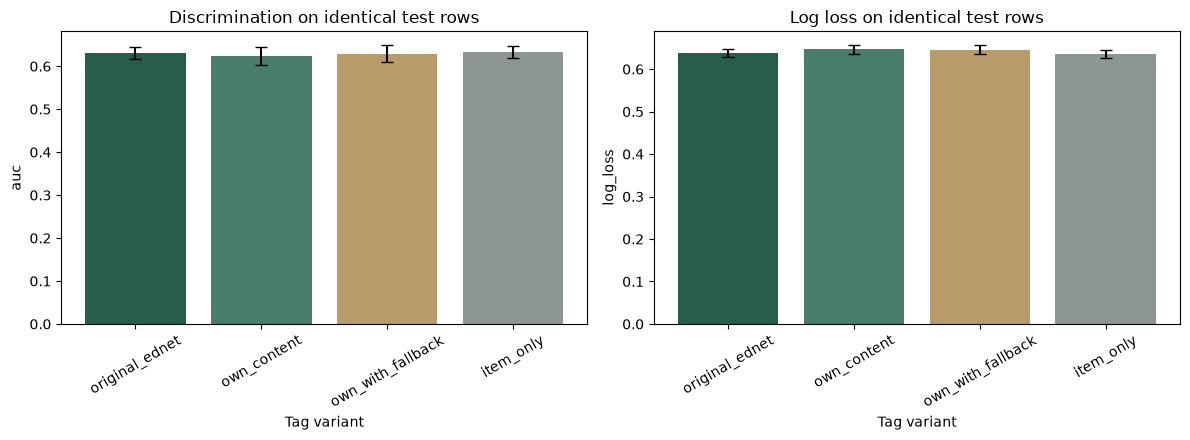

,scope,auc_mean,auc_std,log_loss_mean,log_loss_std,brier_mean,brier_std,accuracy_mean,accuracy_std
variant,,,,,,,,,
original_ednet,all_test,0.630647,0.014664,0.637995,0.009273,0.222645,0.004215,0.645541,0.013453
own_content,all_test,0.624320,0.020472,0.646481,0.009695,0.225415,0.004295,0.642303,0.012633
own_with_fallback,all_test,0.629356,0.019407,0.645616,0.010120,0.224771,0.004596,0.645349,0.013380
item_only,all_test,0.633145,0.014264,0.635721,0.009335,0.222142,0.004313,0.646611,0.010798


In [3]:
data=agg[agg.scope=='all_test'].set_index('variant').loc[['original_ednet','own_content','own_with_fallback','item_only']]
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
x=np.arange(len(data))
for ax,metric,title in [(axes[0],'auc','Discrimination on identical test rows'),(axes[1],'log_loss','Log loss on identical test rows')]:
    ax.bar(x,data[metric+'_mean'],yerr=data[metric+'_std'].fillna(0),capsize=4,color=['#275d4b','#477d69','#b79b68','#8c9692'])
    ax.set(xticks=x,xticklabels=data.index,ylabel=metric,title=title,xlabel='Tag variant')
    ax.tick_params(axis='x',labelrotation=30)
fig.tight_layout();plt.show()
fig.savefig(OUT/'comparison.png',dpi=150,bbox_inches='tight')
display(data)

## 3. Chênh AUC và bất định

Paired bootstrap theo người học trên cùng test rows, 200 lần/seed. CI chỉ phản ánh biến thiên cohort test ở split đó; không có kiểm định tương đương hoặc điều chỉnh multiple comparisons.

,seed,comparison,delta_auc,ci95_low,ci95_high,unit,bootstrap_repeats
0,42,own_content minus original_ednet,-0.002886,-0.019898,0.012498,student_cluster,200
1,42,own_with_fallback minus original_ednet,0.001554,-0.014254,0.015407,student_cluster,200
2,42,item_only minus original_ednet,0.001955,-0.018673,0.021793,student_cluster,200
3,43,own_content minus original_ednet,-0.016799,-0.024846,-0.007089,student_cluster,200
4,43,own_with_fallback minus original_ednet,-0.010229,-0.016672,-0.002207,student_cluster,200
5,43,item_only minus original_ednet,0.006872,-0.007831,0.021588,student_cluster,200
6,44,own_content minus original_ednet,0.000706,-0.009476,0.011075,student_cluster,200
7,44,own_with_fallback minus original_ednet,0.004804,-0.006683,0.016198,student_cluster,200
8,44,item_only minus original_ednet,-0.001331,-0.016774,0.016623,student_cluster,200


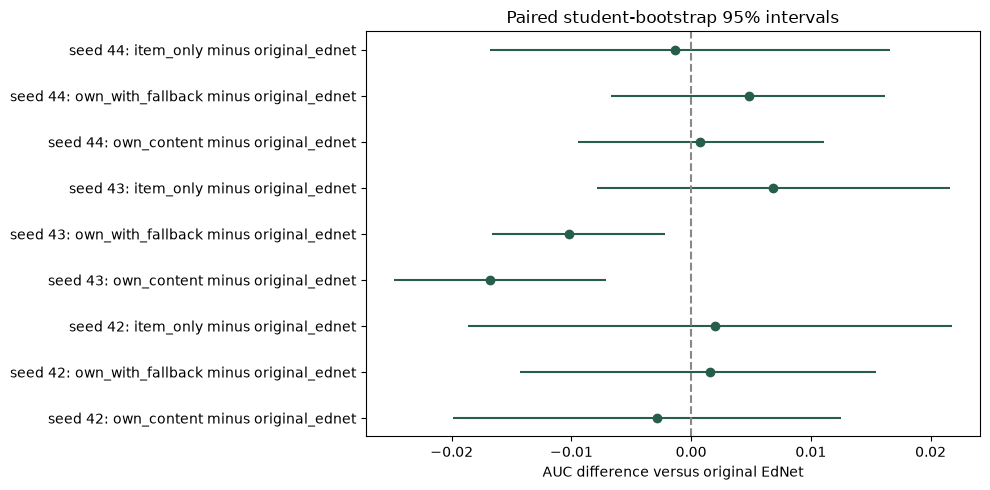

In [4]:
display(ci)
fig,ax=plt.subplots(figsize=(10,5))
labels=[f"seed {r.seed}: {r.comparison}" for r in ci.itertuples()]
y=np.arange(len(ci))
ax.hlines(y,ci.ci95_low,ci.ci95_high,color='#275d4b')
ax.scatter(ci.delta_auc,y,color='#275d4b')
ax.axvline(0,color='#888888',linestyle='--')
ax.set(yticks=y,yticklabels=labels,xlabel='AUC difference versus original EdNet',title='Paired student-bootstrap 95% intervals')
fig.tight_layout();plt.show()
fig.savefig(OUT/'paired_auc.png',dpi=150,bbox_inches='tight')

## 4. Câu có mapping và câu chưa có mapping

Các scope dùng cùng row masks giữa mọi model. Kết quả ở nhóm nhỏ có thể không ổn định. Không chọn kết quả test thuận lợi để thay đổi taxonomy rồi báo lại như holdout.

In [5]:
display(agg.sort_values(['scope','variant']))
assert metrics.converged.all()
for (_,scope),g in metrics.groupby(['seed','scope']):
    assert g.test_attempts.nunique()==1,'Variant row counts differ'
print('Selected models converged; test row counts equal across all variants.')
print('Interaction data, individual predictions, and user splits remain ignored local files.')

,variant,scope,auc_mean,auc_std,log_loss_mean,log_loss_std,brier_mean,brier_std,accuracy_mean,accuracy_std
0,item_only,all_test,0.633145,0.014264,0.635721,0.009335,0.222142,0.004313,0.646611,0.010798
3,original_ednet,all_test,0.630647,0.014664,0.637995,0.009273,0.222645,0.004215,0.645541,0.013453
6,own_content,all_test,0.624320,0.020472,0.646481,0.009695,0.225415,0.004295,0.642303,0.012633
9,own_with_fallback,all_test,0.629356,0.019407,0.645616,0.010120,0.224771,0.004596,0.645349,0.013380
1,item_only,mapped_test,0.632694,0.011919,0.634713,0.008999,0.221672,0.004185,0.647781,0.011920
4,original_ednet,mapped_test,0.627781,0.014168,0.638204,0.009741,0.222685,0.004411,0.646049,0.012985
7,own_content,mapped_test,0.623783,0.018568,0.646297,0.009310,0.225201,0.004119,0.643012,0.013247
10,own_with_fallback,mapped_test,0.626430,0.018771,0.646079,0.009891,0.224911,0.004480,0.645159,0.013711
2,item_only,unmapped_test,0.633693,0.039641,0.649398,0.015598,0.228502,0.006940,0.631798,0.007663
5,original_ednet,unmapped_test,0.662783,0.020200,0.634938,0.002801,0.221993,0.001506,0.638520,0.020824


Selected models converged; test row counts equal across all variants.
Interaction data, individual predictions, and user splits remain ignored local files.


## 5. Chưa thể kết luận gì?

Pilot 600 người, prefix khoảng 200 attempts không đại diện toàn EdNet. Không chứng minh tên kỹ năng đúng, nhóm tối ưu, hoặc mô hình tương đương. Dùng thêm người/lịch sử dài hơn và protocol cố định trước khi chốt luận văn. Student-disjoint evaluation không phải global calendar holdout; test learner responses chỉ cập nhật lịch sử sau khi dự đoán từng batch. DAS3H d=0 ở đây không có latent interactions libFM.

In [6]:
for note in protocol['limits']: print('-',note)
print((ROOT/'docs/DAS3H_RESULTS.md').read_text(encoding='utf-8'))

- Small prefix sample, three splits not independent folds.
- Mapping and clusters are research candidates, not independent gold.
- Prediction performance does not validate names of semantic skills.
- Unmapped OWN items retain item bias but have no skill history.
- Original and OWN differ in number and granularity of skills; no proof of causality or equivalence.
- Interactions and per-user predictions remain private local files; not published.
# DAS3H pilot với bộ tag OWN

600 người học, 37,180 lượt làm đã nộp, 7855 câu khác ID.
Cùng lượt train/validation/test giữa mọi biến thể. Đánh giá online trên người học chưa có trong train, không phải global chronological holdout.

## AUC trung bình trên toàn bộ test

- item_only: AUC 0.633145 ± 0.014264; log loss 0.635721.
- original_ednet: AUC 0.630647 ± 0.014664; log loss 0.637995.
- own_content: AUC 0.624320 ± 0.020472; log loss 0.646481.
- own_with_fallback: AUC 0.629356 ± 0.019407; log loss 0.645616.

Độ lệch chuẩn giữa ba seed, không phải k